# SAR Flood Segmentation - ETCI 2021

Semantic segmentation of flooded areas in Sentinel-1 SAR imagery with a U-Net (ResNet34 encoder). This notebook is for EDA only.

### Context
I am building a deep learning-based semantic segmentation system to automate the detection of flooded regions using SAR imagery. SAR is highly advantageous for disaster response as it penetrates cloud cover and operates day and night. However, it presents unique physical characteristics, such as speckle noise and radar shadows. The core of this system will be a U-Net architecture utilizing a pre-trained ResNet encoder. A defining characteristic of the landscape I am operating in is a severe data class imbalance.

My main goals is to develop a stable, generalizable segmentation model capable of accurately distinguishing flood water from diverse background terrains in SAR data.

- Development notes:
    - To get access to Kaggle's free GPU, this notebook is run on Kaggle, so the data paths (`/kaggle/input/...`) will differ in a local environment.
    - The notebook uses some satellite imagery (SAR) concepts, which are explained where they first appear (polarization, backscatter, the RGB composite).
    - The utility functions are kept inside the notebook, because it is run on Kaggle as a single file.
    - The approach builds on an earlier project of mine from my master's studies; it is adapted and extended here for this task.

In [ ]:
import os
import random
from glob import glob

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

# Set up matplotlib for Jupyter
%matplotlib inline


from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

## Dataset: ETCI 2021 Flood Detection

**Source.** Kaggle dataset [Flood Detection (ECTI 2021 by NASA)](https://www.kaggle.com/datasets/maelysboudier/ecti-2021), the data of the [ETCI 2021 Flood Detection competition](https://nasa-impact.github.io/etci2021/) (NASA IMPACT). According to the competition description the training set consists of 33,405 tiles of 256×256 pixels per polarization (66,810 images in total, VV and VH), and there are 10,400 validation and 12,348 test tiles per polarization. 

**Polarization (VV and VH).** Sentinel-1 is a radar satellite: it sends out a microwave pulse and measures the signal that bounces back from the ground. The pulse is a wave that oscillates in a fixed direction, either vertically (V) or horizontally (H). This is called its polarization.

- **VV** – sent vertical, received vertical. Responds strongly to surface roughness, and is good for telling water from land.
- **VH** – sent vertical, received horizontal. The returned signal changes direction when it hits complex surfaces such as vegetation or buildings, so VH shows volume and structure.

Calm water acts like a mirror: it reflects the pulse away from the satellite, so it appears dark in both channels. Land scatters the signal back, so it appears brighter. Using both polarizations gives the model two different views of the same pixel.

The tiles were cut from 54 labelled Sentinel-1 C-band SAR scenes (Interferometric Wide Swath, 5×20 m native resolution) processed with the HyP3 pipeline. Training tiles come with a flood mask and a permanent water-body mask; the validation release (`val_without_ref_labels`) comes without flood labels.

**Layout.** `<split>/<region>_<datetime>/tiles/{vv,vh,flood_label,water_body_label}/<region>_<datetime>_x-<i>_y-<j>_<vv|vh>.png`

**Use here.** I will analyse the train split, and clean and split it into 80/20  training and validation tiles; I will use the validation release without labels as unlabelled test set.

In [ ]:
# You probably don't see it however, the data directory has the following format .../<split(location probably)>/<region>/tiles/vv 
# so I will try to find the  split folders first

split_counts = Counter(str(Path(d).parents[2]) for d in glob('/kaggle/input/**/tiles/vv', recursive=True))
print(split_counts) 

train_dir = next(s for s in split_counts if 'train' in os.path.basename(s).lower())
test_dir = next(s for s in split_counts if any(k in os.path.basename(s).lower() for k in ('val', 'test')))

print('train_dir:', train_dir)
print('test_dir :', test_dir)

Counter({'/kaggle/input/datasets/tinasikhbse/flood-detection/ecti2021/train/train': 31, '/kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/train/train': 31, '/kaggle/input/datasets/tinasikhbse/flood-detection/ecti2021/val_without_ref_labels/val': 10, '/kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/val_without_ref_labels/val': 10})
train_dir: /kaggle/input/datasets/tinasikhbse/flood-detection/ecti2021/train/train
test_dir : /kaggle/input/datasets/tinasikhbse/flood-detection/ecti2021/val_without_ref_labels/val


**The four files of each tile.** Every 256×256 tile is stored as four PNG images that cover the same ground area, pixel by pixel:

| File | What it is | Role |
|---|---|---|
| **VV** | Sentinel-1 radar image, vertical-in / vertical-out polarization | Model input |
| **VH** | Sentinel-1 radar image, vertical-in / horizontal-out polarization | Model input |
| **flood_label** | Binary mask: 255 = flooded pixel, 0 = not flooded | Target (what the model must predict) |
| **water_body_label** | Binary mask: 255 = permanent water (rivers, lakes, sea), 0 = other | Extra context, not the target |

VV and VH are two views of the same scene. Water is dark in both, and the two channels together show more than either one alone. The flood label marks the water that is there because of the flood. The water-body label marks water that is always there, so it helps separate a flooded field from a normal river.

Pixel value 255 in both VV and VH means "no radar data" (the satellite did not cover that part of the tile).

In [ ]:
def tile_paths(vv_path):
    """Given the path of a VV image, return the paths of its 3 sibling files:
    (VH image, flood label, water-body label)."""

    # Example: vv_path = ".../tiles/vv/abc_x-0_y-0_vv.png"
    # dirname(vv_path)           -> ".../tiles/vv"
    # dirname(dirname(vv_path))  -> ".../tiles"   (the folder that holds vv, vh, flood_label, water_body_label)
    tiles_dir = os.path.dirname(os.path.dirname(vv_path))

    # File name without the "_vv.png" ending, i.e. the tile's id: "abc_x-0_y-0"
    # All four files of one tile share this id; only the suffix differs.
    stem = os.path.basename(vv_path)[:-len('_vv.png')]

    def pick(folder):
        """Find the label file in `folder`. Label file names differ between dataset copies:
        some are named "<stem>.png", others "<stem>_vv.png". Try both and return the one that exists."""
        for cand in (stem + '.png', stem + '_vv.png'):
            p = os.path.join(tiles_dir, folder, cand)
            if os.path.exists(p):
                return p
        # Neither exists: return the first naming guess anyway.
        # scan_tile() will then see that the file is missing and mark this tile as not ok.
        return os.path.join(tiles_dir, folder, stem + '.png')

    # VH image:  tiles/vh/<stem>_vh.png   (always has the "_vh" suffix, so no guessing is needed)
    # Labels:    found with pick(), because their naming varies
    return os.path.join(tiles_dir, 'vh', stem + '_vh.png'), pick('flood_label'), pick('water_body_label')


# I will scan every tile and build a table tiles_df with the following columns:
SCAN_COLUMNS = [
    'vv_image_path', 'vh_image_path',          # paths of the two radar images (model input)
    'flood_label_path', 'water_body_label_path',  # paths of the two masks
    'ok',                                      # True if all 4 files exist and can be read
    'blank',                                   # True if the whole tile is white (255) = no radar data
    'white_frac',                              # fraction of "no data" pixels (0.0 to 1.0)
    'flood_px',                                # number of flooded pixels in the flood label
    'water_px',                                # number of permanent-water pixels in the water-body label
    'flood_in_void_px',                        # flood-labelled pixels that lie in "no data" areas (suspicious)
    'vv_mean', 'vv_std',                       # mean / std of VV pixel values (helps spot constant tiles)
]


def scan_tile(vv_path):
    """Read all four files of a tile once and record the statistics that I will use in the data analysis below.

    blank            : VV and VH are completely white (255) -> the tile contains no SAR data at all
    white_frac       : share of 'no-data' pixels (VV == 255 and VH == 255)
    flood_px         : number of flood pixels in the flood label
    water_px         : number of water pixels in the water-body label
    flood_in_void_px : flood-labelled pixels that lie inside no-data pixels
    """
    vh, flood, water = tile_paths(vv_path)
    ok = all(os.path.exists(p) for p in (vh, flood, water))
    stats = (False, 0.0, -1, -1, 0, 0.0, 0.0)
    if ok:
        vv_img, vh_img = cv2.imread(vv_path, 0), cv2.imread(vh, 0)
        fl_img, wb_img = cv2.imread(flood, 0), cv2.imread(water, 0)
        if any(x is None for x in (vv_img, vh_img, fl_img, wb_img)):
            ok = False
        else:
            void = (vv_img == 255) & (vh_img == 255)
            stats = (bool(void.all()), float(void.mean()), int((fl_img > 0).sum()), int((wb_img > 0).sum()),
                     int(((fl_img > 0) & void).sum()), float(vv_img.mean()), float(vv_img.std()))
    return (vv_path, vh, flood, water, ok) + stats


def scan_split(split_dir):
    vv_paths = sorted(glob(os.path.join(split_dir, '*', 'tiles', 'vv', '*_vv.png')))
    with ThreadPoolExecutor(max_workers=16) as ex:
        rows = list(tqdm(ex.map(scan_tile, vv_paths), total=len(vv_paths), desc=os.path.basename(split_dir)))
    df = pd.DataFrame(rows, columns=SCAN_COLUMNS)
    df['region'] = [Path(p).parents[2].name for p in df['vv_image_path']]
    return df


# One pass over the training tiles
INDEX_CSV = 'train_tile_index.csv'
n_on_disk = len(glob(os.path.join(train_dir, '*', 'tiles', 'vv', '*_vv.png')))
tiles_df = None
if os.path.exists(INDEX_CSV):
    cached = pd.read_csv(INDEX_CSV)
    if (len(cached) == n_on_disk and set(SCAN_COLUMNS) <= set(cached.columns)
            and cached['vv_image_path'].str.startswith(train_dir).all()):
        tiles_df = cached
if tiles_df is None:
    tiles_df = scan_split(train_dir)
    tiles_df.to_csv(INDEX_CSV, index=False)

n_broken = int((~tiles_df['ok']).sum())
print(f'Training tiles indexed: {len(tiles_df)} ({n_broken} incomplete or unreadable tiles dropped)')
tiles_df = tiles_df[tiles_df['ok']].reset_index(drop=True)
tiles_df.head()

train:   0%|          | 0/33405 [00:00<?, ?it/s]

Training tiles indexed: 33405 (0 incomplete or unreadable tiles dropped)


,vv_image_path,vh_image_path,flood_label_path,water_body_label_path,ok,blank,white_frac,flood_px,water_px,flood_in_void_px,vv_mean,vv_std,region
0,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,True,False,0.705963,0,0,0,180.020599,116.180190,bangladesh_20170314t115609
1,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,True,False,0.857803,0,0,0,218.739853,89.059190,bangladesh_20170314t115609
2,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,True,False,0.869659,0,0,0,221.763153,85.852827,bangladesh_20170314t115609
3,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,True,False,0.880981,0,0,0,224.650269,82.571638,bangladesh_20170314t115609
4,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,/kaggle/input/datasets/tinasikhbse/flood-detec...,True,False,0.891663,0,0,0,227.373962,79.255546,bangladesh_20170314t115609


Below I will buld a RGB composite
Radar (SAR) images have no natural colour: each channel only records how strongly the signal came back, so a single channel (VV or VH) is just a grayscale picture that is hard to interpret. Remote sensing, the field that works with satellite imagery, commonly combines several channels into a **false-colour composite**, where each channel is assigned to red, green or blue. This lets a person see in one picture what separate grayscale images would show only one at a time.

For Sentinel-1, a standard composie is **R = VV, G = VH, B = VV/VH ratio**. Different surfaces get different colours: water, vegetation and built-up areas look distinct, which makes it easier to inspect the data by eye. The composite is used here for visual inspection only. The colours are not real, and the model can learn from the raw VV and VH channels directly.

In [ ]:
def s1_to_rgb(vv_image, vh_image):
    """Combine VV and VH (values already scaled to 0-1) into one 3-channel image for plotting."""
    eps = 1e-06  # tiny number so I never divide by zero where VH = 0

    # Third channel: VV / VH ratio.
    # nan_to_num replaces NaN/inf (from bad divisions) with 0,
    # clip forces every value into [0, 1] so it is a valid colour channel.
    ratio_image = np.clip(np.nan_to_num(vv_image / (vh_image + eps), 0), 0, 1)

    # Stack along a new last axis -> shape (H, W, 3) = (red, green, blue)
    rgb_image = np.stack((vv_image, vh_image, ratio_image), axis=2)
    return rgb_image

### Data analysis of the raw training tiles

I examine the tiles for several things: (1) the fles are complete and consistent, (2) what the images and labels look like, (3) which tiles are unusable, and (4) how strongly classes and regions differ.

#### 1. Structure and integrity
Each tile consists of four files (VV, VH, flood label, water-body label) that must exist and share the same tile name. The check counts the files per folder and region, and verifies that every VV tile has all of its three partner files.

,vv,vh,flood_label,water_body_label,equal_counts
region,,,,,
bangladesh_20170314t115609,2068,2068,2068,2068,True
bangladesh_20170606t115613,2068,2068,2068,2068,True
bangladesh_20170712t115615,2068,2068,2068,2068,True
nebraska_20170108t002112,984,984,984,984,True
nebraska_20170213t002121,1008,1008,1008,1008,True
nebraska_20170309t002110,1008,1008,1008,1008,True
nebraska_20170402t002111,1008,1008,1008,1008,True
nebraska_20170508t002113,1008,1008,1008,1008,True
nebraska_20170520t002113,1008,1008,1008,1008,True


Files per folder (all regions): {'vv': 33405, 'vh': 33405, 'flood_label': 33405, 'water_body_label': 33405}
Regions whose four folders hold the same number of files: 31 / 31
Tiles for which VV, VH, flood label and water-body label were all found and readable: 33405 / 33405


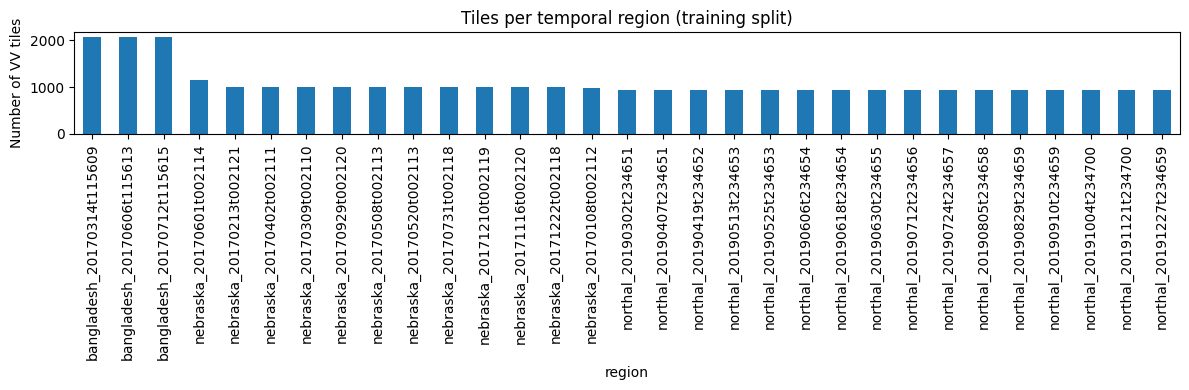

In [ ]:
# Number of files in each of the four folders, per temporal region
FOLDERS = ('vv', 'vh', 'flood_label', 'water_body_label')
rows = []
for region_dir in sorted(glob(train_dir + '/*/')):
    region = os.path.basename(region_dir.rstrip('/'))
    rows.append({'region': region,
                 **{f: len(glob(os.path.join(region_dir, 'tiles', f, '*.png'))) for f in FOLDERS}})
structure_df = pd.DataFrame(rows).set_index('region')
structure_df['equal_counts'] = structure_df[list(FOLDERS)].nunique(axis=1) == 1
display(structure_df)

print('Files per folder (all regions):', structure_df[list(FOLDERS)].sum().to_dict())
print('Regions whose four folders hold the same number of files:',
      f"{int(structure_df['equal_counts'].sum())} / {len(structure_df)}")
print(f'Tiles for which VV, VH, flood label and water-body label were all found and readable: '
      f'{len(tiles_df)} / {len(tiles_df) + n_broken}')

fig, ax = plt.subplots(figsize=(12, 4))
structure_df['vv'].sort_values(ascending=False).plot.bar(ax=ax)
ax.set_title('Tiles per temporal region (training split)')
ax.set_ylabel('Number of VV tiles')
plt.tight_layout()
plt.show()

#### 2. What the tiles look like
Two tiles with flood and two without. The composite image is the model input: VV, VH and the ratio VV/VH as a pseudo-colour image. The water-body label shows permanent water before the event; the flood label marks the water present after the flood.

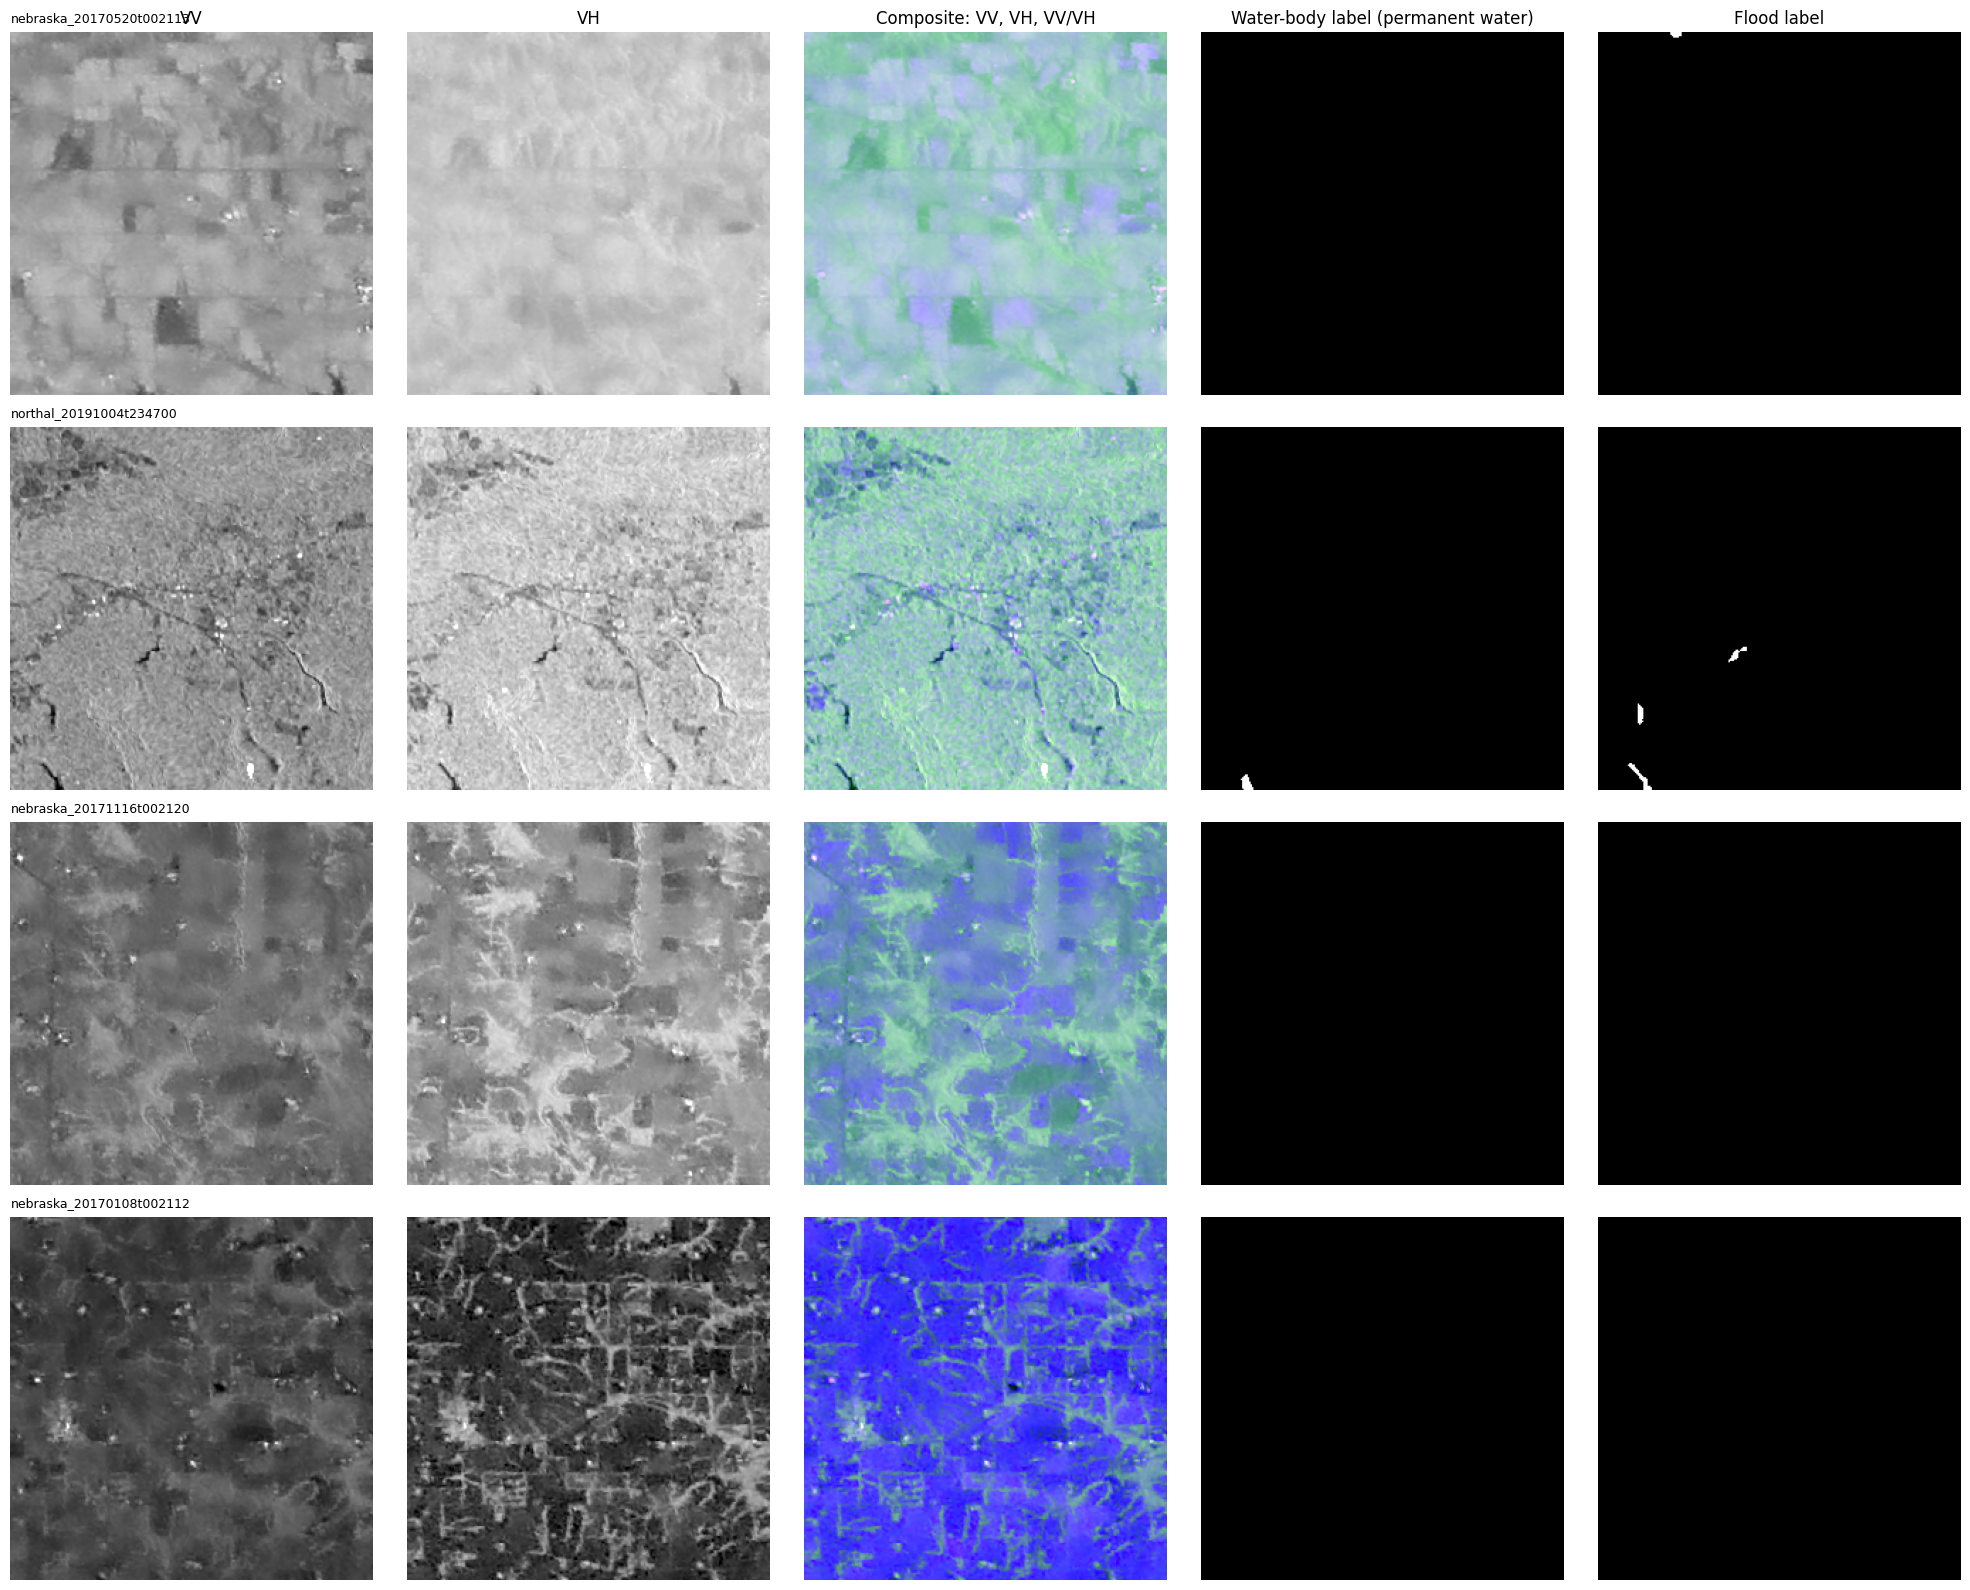

In [16]:
# Four random tiles: two with flood, two without (blank tiles excluded here, they are analysed below)
valid_tiles = tiles_df[~tiles_df['blank']]
with_flood = valid_tiles[valid_tiles['flood_px'] > 0]
no_flood = valid_tiles[valid_tiles['flood_px'] == 0]
sample_rows = pd.concat([with_flood.sample(min(2, len(with_flood)), random_state=3),
                         no_flood.sample(min(2, len(no_flood)), random_state=3)])

fig, axes = plt.subplots(len(sample_rows), 5, figsize=(20, 4 * len(sample_rows)), squeeze=False)
for r, row in enumerate(sample_rows.itertuples()):
    vv, vh = cv2.imread(row.vv_image_path, 0), cv2.imread(row.vh_image_path, 0)
    panels = [(vv, 'VV', True), (vh, 'VH', True),
              (s1_to_rgb(vv / 255.0, vh / 255.0), 'Composite: VV, VH, VV/VH', False),
              (cv2.imread(row.water_body_label_path, 0), 'Water-body label (permanent water)', True),
              (cv2.imread(row.flood_label_path, 0), 'Flood label', True)]
    for c, (img, title, gray) in enumerate(panels):
        if gray:
            axes[r, c].imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            axes[r, c].imshow(img)
        axes[r, c].set_title(title if r == 0 else '')
        axes[r, c].axis('off')
    axes[r, 0].text(0, -8, row.region, fontsize=9)
plt.tight_layout()
plt.show()

#### 3. Pixel values
The images are 8-bit (0-255). The following checks showw the value range of a regular tile, of a blank tile, and whether the labels are strictly binary.

In [17]:
def describe(path, name):
    a = cv2.imread(path, 0)
    u = np.unique(a)
    print(f'{name:<30} min={a.min():>3}  max={a.max():>3}  distinct values={len(u):>3}'
          + (f'  -> {u.tolist()}' if len(u) <= 4 else ''))


ex_valid = with_flood.iloc[0] if len(with_flood) else valid_tiles.iloc[0]
print('Regular tile:', ex_valid['vv_image_path'].split('/')[-1])
describe(ex_valid['vv_image_path'], '  VV image')
describe(ex_valid['vh_image_path'], '  VH image')
describe(ex_valid['water_body_label_path'], '  water-body label')
describe(ex_valid['flood_label_path'], '  flood label')

blank_tiles_df = tiles_df[tiles_df['blank']]
if len(blank_tiles_df):
    ex_blank = blank_tiles_df.iloc[0]
    print('\nBlank tile:', ex_blank['vv_image_path'].split('/')[-1])
    describe(ex_blank['vv_image_path'], '  VV image')
    describe(ex_blank['vh_image_path'], '  VH image')
    describe(ex_blank['water_body_label_path'], '  water-body label')
    describe(ex_blank['flood_label_path'], '  flood label')

# Are all labels strictly binary (0 / 255)?  Checked on a random sample of 500 label files of each kind
label_values = {'flood': set(), 'water body': set()}
for p in tiles_df['flood_label_path'].sample(min(500, len(tiles_df)), random_state=0):
    label_values['flood'] |= set(np.unique(cv2.imread(p, 0)).tolist())
for p in tiles_df['water_body_label_path'].sample(min(500, len(tiles_df)), random_state=0):
    label_values['water body'] |= set(np.unique(cv2.imread(p, 0)).tolist())
print('\nValues found in 500 random flood labels / water-body labels:', label_values)

Regular tile: bangladesh_20170314t115609_x-0_y-31_vv.png
  VV image                     min=  0  max=255  distinct values=195
  VH image                     min=  0  max=255  distinct values=199
  water-body label             min=  0  max=  0  distinct values=  1  -> [0]
  flood label                  min=  0  max=255  distinct values=  2  -> [0, 255]

Blank tile: bangladesh_20170314t115609_x-0_y-35_vv.png
  VV image                     min=255  max=255  distinct values=  1  -> [255]
  VH image                     min=255  max=255  distinct values=  1  -> [255]
  water-body label             min=  0  max=  0  distinct values=  1  -> [0]
  flood label                  min=  0  max=  0  distinct values=  1  -> [0]

Values found in 500 random flood labels / water-body labels: {'flood': {0, 255}, 'water body': {0, 255}}


#### 4. Blank and cut tiles: evidence
A tile is called *blank* if VV **and** VH are completely white (255 everywhere), i.e. the satellite swath did not cover the tile and it contains no SAR data. The figures below show how many such tiles there are, that 255 is by far the most common constant value (a few all-black tiles also exist), and that blank tiles still carry labels, which makes them harmful for training.

Tiles with 100 % no-data pixels (blank):     6191  (18.5 %)
Tiles partly cut (0 % < no-data < 100 %):    21438  (64.2 %)
Tiles without any no-data pixel:             5776  (17.3 %)


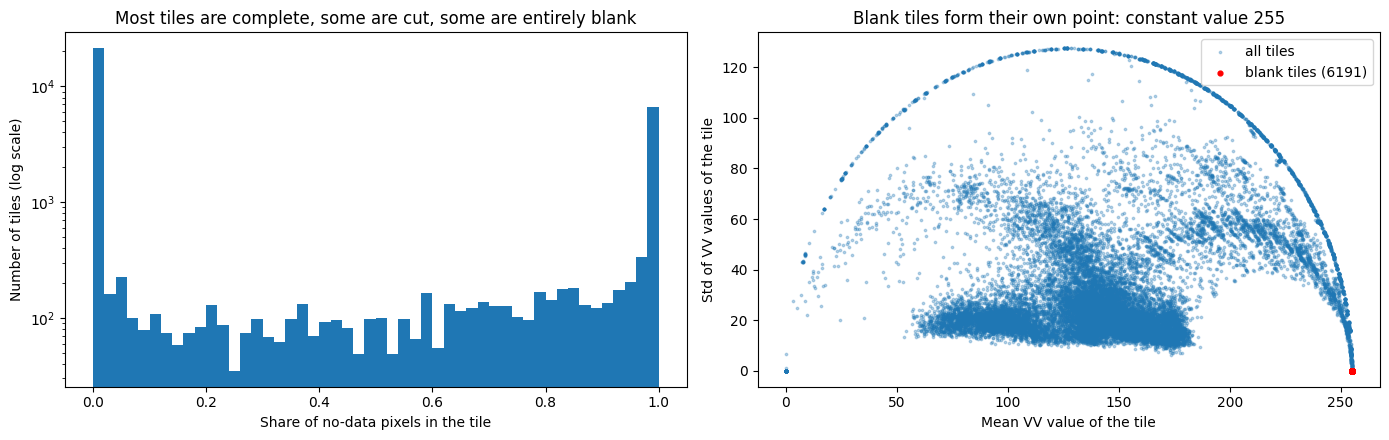

In [ ]:
# how much of each tile contains no SAR data (VV == 255 and VH == 255)? 
wf = tiles_df['white_frac']
n_full, n_none = int((wf == 1).sum()), int((wf == 0).sum())
n_part = len(tiles_df) - n_full - n_none
print(f'Tiles with 100 % no-data pixels (blank):   {n_full:>6}  ({100 * n_full / len(tiles_df):.1f} %)')
print(f'Tiles partly cut (0 % < no-data < 100 %):   {n_part:>6}  ({100 * n_part / len(tiles_df):.1f} %)')
print(f'Tiles without any no-data pixel:           {n_none:>6}  ({100 * n_none / len(tiles_df):.1f} %)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(wf, bins=50)
axes[0].set_yscale('log')
axes[0].set_xlabel('Share of no-data pixels in the tile')
axes[0].set_ylabel('Number of tiles (log scale)')
axes[0].set_title('Most tiles are complete, some are cut, some are entirely blank')

axes[1].scatter(tiles_df['vv_mean'], tiles_df['vv_std'], s=3, alpha=0.3, label='all tiles')
b = tiles_df[tiles_df['blank']]
axes[1].scatter(b['vv_mean'], b['vv_std'], s=12, color='red', label=f'blank tiles ({len(b)})')
axes[1].set_xlabel('Mean VV value of the tile')
axes[1].set_ylabel('Std of VV values of the tile')
axes[1].set_title('Blank tiles form their own point: constant value 255')
axes[1].legend()
plt.tight_layout()
plt.show()

In [25]:
# is 255 the only 'constant tile' value? 
const = tiles_df[tiles_df['vv_std'] == 0]
print('\nTiles whose VV image is constant (std = 0), by value:', const['vv_mean'].round(1).value_counts().to_dict())
print('Constant-VV tiles that are blank (VV and VH white):', int(const['blank'].sum()), '/', len(const))


Tiles whose VV image is constant (std = 0), by value: {255.0: 6194, 0.0: 78}
Constant-VV tiles that are blank (VV and VH white): 6191 / 6272


This means:

- 6,272 tiles have a VV image with no variation at all (std = 0): every pixel in the tile has the same value.
- Of those, 6,194 are all 255 (white) and 78 are all 0 (black). 6,194 + 78 = 6,272.
- 6,191 of the 6,272 are blank, i.e. both VV and VH are completely white.
- The remaining 81 constant tiles are 3 tiles with a white VV but a VH that is not completely white, and the 78 all-black tiles. Black is not the "no data" value, but these tiles carry no information either.

In [28]:
# do blank tiles still carry labels? 
bl = tiles_df['blank']
table = pd.DataFrame({
    'blank tiles': [int((bl & (tiles_df['flood_px'] > 0)).sum()), int((bl & (tiles_df['flood_px'] == 0)).sum()),
                    int((bl & (tiles_df['water_px'] > 0)).sum()), int((bl & (tiles_df['water_px'] == 0)).sum())],
    'non-blank tiles': [int((~bl & (tiles_df['flood_px'] > 0)).sum()), int((~bl & (tiles_df['flood_px'] == 0)).sum()),
                        int((~bl & (tiles_df['water_px'] > 0)).sum()), int((~bl & (tiles_df['water_px'] == 0)).sum())],
}, index=['flood label NOT empty', 'flood label empty', 'water-body label NOT empty', 'water-body label empty'])
display(table)
n_noisy = int((bl & ((tiles_df['flood_px'] > 0) | (tiles_df['water_px'] > 0))).sum())
print(f'{n_noisy} noisy images')

,blank tiles,non-blank tiles
flood label NOT empty,472,10462
flood label empty,5719,16752
water-body label NOT empty,1787,6570
water-body label empty,4404,20644


1857 noisy images


so 1857 blank tiles carry a non-empty label: there is nothing to see in the image, yet the label claims water.

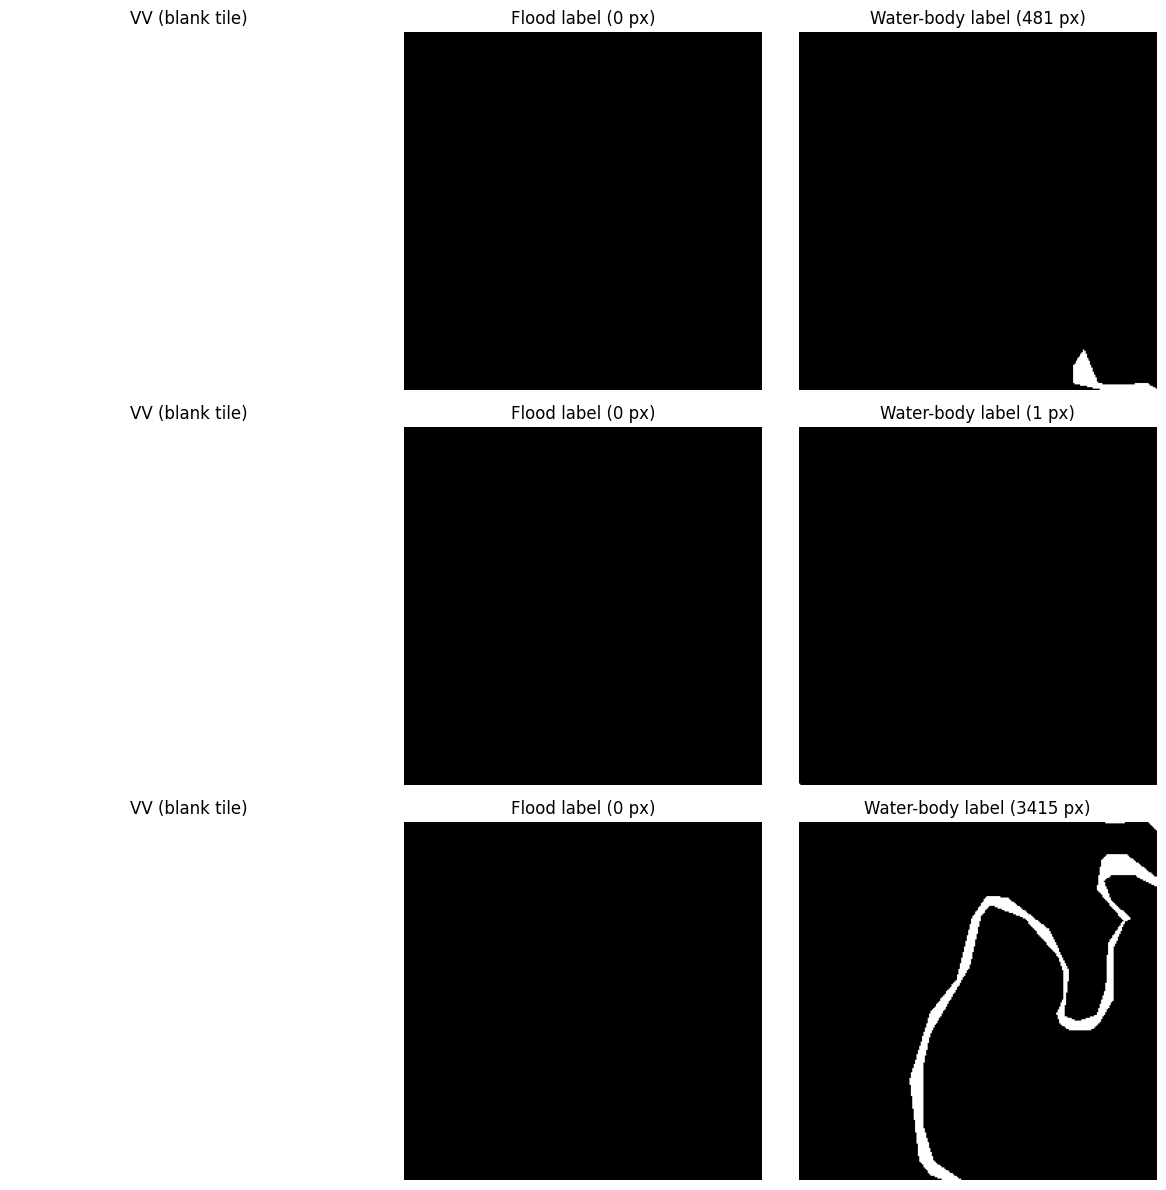

In [29]:
# examples: blank image, label present 
bad_blank = b[(b['flood_px'] > 0) | (b['water_px'] > 0)]
examples = bad_blank.head(3) if len(bad_blank) else b.head(3)
if len(examples):
    fig, axes = plt.subplots(len(examples), 3, figsize=(12, 4 * len(examples)), squeeze=False)
    for r, row in enumerate(examples.itertuples()):
        for c, (path, title) in enumerate([(row.vv_image_path, 'VV (blank tile)'),
                                           (row.flood_label_path, f'Flood label ({row.flood_px} px)'),
                                           (row.water_body_label_path, f'Water-body label ({row.water_px} px)')]):
            axes[r, c].imshow(cv2.imread(path, 0), cmap='gray', vmin=0, vmax=255)
            axes[r, c].set_title(title)
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()

In [30]:
# partly cut tiles: labels inside the no-data area 
nb = tiles_df[~bl]
part = nb[nb['flood_in_void_px'] > 0]
share = 100 * nb['flood_in_void_px'].sum() / max(nb['flood_px'].sum(), 1)
print(f'\nNon-blank tiles with flood-labelled pixels inside the no-data area: {len(part)} '
      f'({share:.2f} % of all flood pixels of non-blank tiles)')


Non-blank tiles with flood-labelled pixels inside the no-data area: 1087 (8.38 % of all flood pixels of non-blank tiles)


#### 5. Regions differ strongly

The training tiles come from several temporal regions (a region at one acquisition date). The table shows how tile count, blank share and amount of flood differ between them.

,tiles,blank tiles (%),flood tiles (%),flood pixels (%)
region,,,,
bangladesh_20170314t115609,2068,21.03,37.42,3.49
bangladesh_20170606t115613,2068,20.99,37.39,3.49
bangladesh_20170712t115615,2068,21.03,37.35,3.49
nebraska_20170213t002121,1008,18.45,29.08,3.40
northal_20190805t234658,936,16.77,48.40,2.19
northal_20190724t234657,936,16.77,48.40,2.19
northal_20190910t234659,936,16.77,48.14,2.19
northal_20190712t234656,936,16.77,48.27,2.19
northal_20190630t234655,936,16.77,48.27,2.19


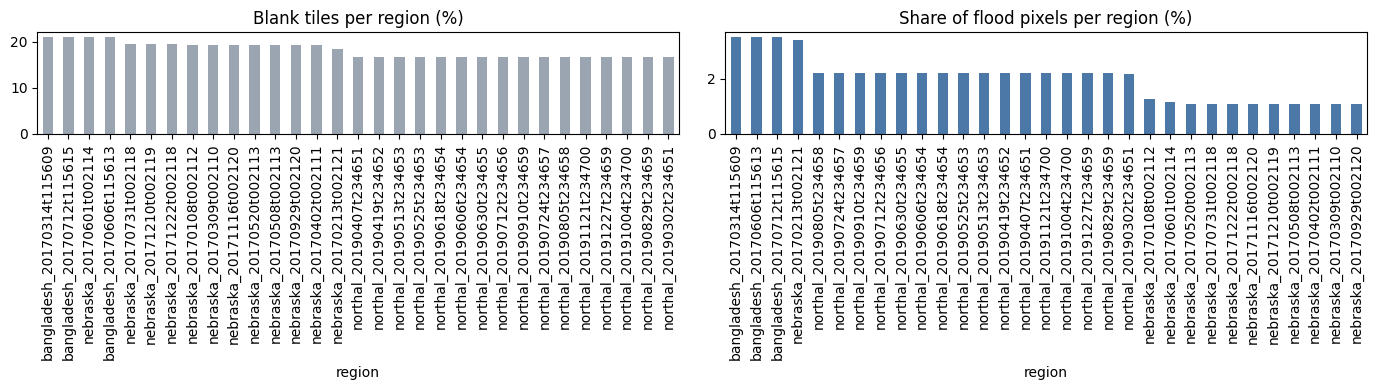

In [19]:
nb = tiles_df[~tiles_df['blank']]
region_stats = pd.DataFrame({
    'tiles': tiles_df.groupby('region').size(),
    'blank tiles (%)': 100 * tiles_df.groupby('region')['blank'].mean(),
    'flood tiles (%)': 100 * nb.groupby('region')['flood_px'].apply(lambda s: (s > 0).mean()),
    'flood pixels (%)': 100 * nb.groupby('region')['flood_px'].sum() / (nb.groupby('region').size() * 256 * 256),
}).round(2).sort_values('flood pixels (%)', ascending=False)
display(region_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
region_stats['blank tiles (%)'].sort_values(ascending=False).plot.bar(ax=axes[0], color='#9aa5b1')
axes[0].set_title('Blank tiles per region (%)')
region_stats['flood pixels (%)'].sort_values(ascending=False).plot.bar(ax=axes[1], color='#4c78a8')
axes[1].set_title('Share of flood pixels per region (%)')
plt.tight_layout()
plt.show()

#### 6. Why water can be detected: backscatter of flooded vs. non-flooded pixels
Open water reflects the radar signal away from the sensor, so it appears dark in both polarizations. The histograms compare the pixel values inside and outside the flood mask on 300 random tiles that contain flood (no-data pixels excluded).

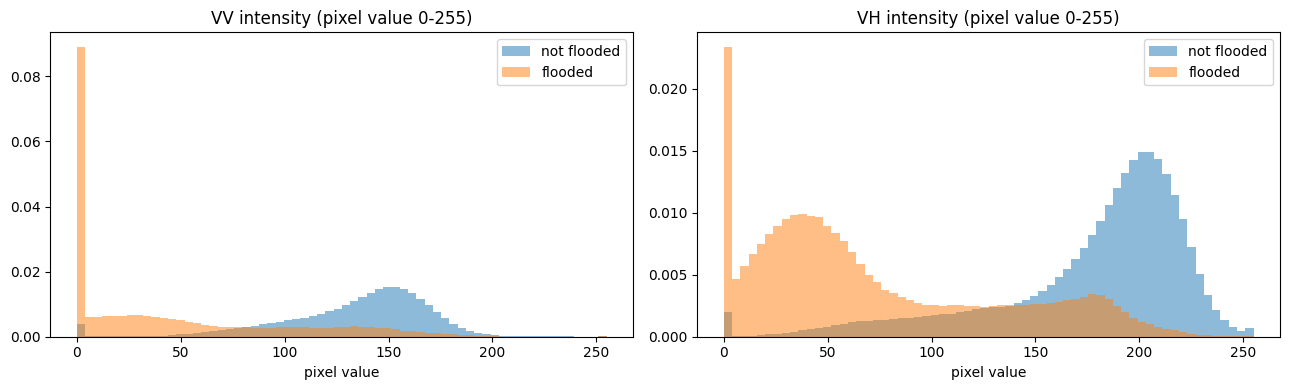

Mean VV: flooded 46.6 vs not flooded 134.7
Mean VH: flooded 71.8 vs not flooded 177.8


In [20]:
# Backscatter of flooded vs. non-flooded pixels (300 random tiles that contain flood, no-data pixels excluded)
samp = with_flood.sample(min(300, len(with_flood)), random_state=0)
vv_f, vv_b, vh_f, vh_b = [], [], [], []
for row in samp.itertuples():
    vv, vh = cv2.imread(row.vv_image_path, 0), cv2.imread(row.vh_image_path, 0)
    flood_mask = cv2.imread(row.flood_label_path, 0) > 0
    valid_px = ~((vv == 255) & (vh == 255))
    vv_f.append(vv[flood_mask & valid_px]); vv_b.append(vv[~flood_mask & valid_px])
    vh_f.append(vh[flood_mask & valid_px]); vh_b.append(vh[~flood_mask & valid_px])
vv_f, vv_b, vh_f, vh_b = map(np.concatenate, (vv_f, vv_b, vh_f, vh_b))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (f, b_, name) in zip(axes, [(vv_f, vv_b, 'VV'), (vh_f, vh_b, 'VH')]):
    ax.hist(b_, bins=64, range=(0, 255), density=True, alpha=0.5, label='not flooded')
    ax.hist(f, bins=64, range=(0, 255), density=True, alpha=0.5, label='flooded')
    ax.set_title(f'{name} intensity (pixel value 0-255)')
    ax.set_xlabel('pixel value')
    ax.legend()
plt.tight_layout()
plt.show()
print(f'Mean VV: flooded {vv_f.mean():.1f} vs not flooded {vv_b.mean():.1f}')
print(f'Mean VH: flooded {vh_f.mean():.1f} vs not flooded {vh_b.mean():.1f}')

#### Findings and decisions

- **Structure:** the four folders hold matching files for every tile, so VV, VH and both labels can be paired by file name (see the integrity table).
- **Labels:** the water-body label marks permanent water before the event and the flood label marks water after the event; both are binary masks (0 / 255). A tile is a *flood tile* when its flood label contains at least one flood pixel.
- **Blank tiles:** a part of the tiles is entirely white in VV and VH (constant value 255, standard deviation 0); 255 is by far the most common constant value, and 78 further tiles are constant 0 (all black). The blank tiles contain no infrmation, yet many of them carry non-empty flood or water-body labels, so training on them would teach the model to predict water on pure noise. **Decision: remove all blank tiles.**
- **Partly cut tiles:** many tiles are only partly covered by the swath. They still contain valid SAR data and are kept. A noticeable share of the flood labels lies inside the no-data area (1,087 tiles, 8.38 % of all flood pixels of non-blank tiles, see the last printed line of section 4); ignoring no-data pixels in the loss would be a worthwhile improvement.
- **Regions:** flood share and blank share vary considerably between regions. A purely random split by tile therefore lets tiles of the same region appear in training and validation; the unlabelled test tiles cannot serve as a check against this, so the split into training and validation tiles has to be made with care.
- **Signal:** flooded pixels are clearly darker than the rest in VV and VH, consistent with radar physics. VV, VH and their ratio are therefore used as the three input channels.
- **Imbalance:** flood pixels are a very small fraction of all pixels (class-distribution plots below), which motivates undersampling of background tiles and class-weighted losses in the experiments.